In [1]:
# Import necessary libraries for data manipulation, visualization, and clustering
# Импорт необходимых библиотек для обработки данных, визуализации и кластеризации
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.stats import f_oneway

In [2]:
# Load the dataset and display basic statistical summaries
# Загрузка набора данных и отображение базовых статистических сводок
df = pd.read_csv('Econom_Cities_data.csv', sep=';', decimal=',')
display(df.describe())

,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


In [3]:
# Identify anomalies where Work, Price, or Salary have negative values
# Выявление аномалий, где значения Work, Price или Salary отрицательны
anomalies = df[(df['Work'] < 0) | (df['Price'] < 0) | (df['Salary'] < 0)]
print("Аномальные данные")
display(anomalies)

Аномальные данные


,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


In [4]:
# Filter out negative data points to create a clean analytical dataset
# Фильтрация отрицательных значений для создания чистого аналитического набора данных
df_clean = df[(df['Work'] >= 0) & (df['Price'] >= 0) & (df['Salary'] >= 0)].copy()
print(f"Данные успешно очищены. Осталось городов: {df_clean.shape[0]}")
df_clean


Данные успешно очищены. Осталось городов: 46


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5
5,Buenos_Aires,1971,56.1,12.5
7,Caracas,2041,61.0,10.9
8,Chicago,1924,73.9,61.9
9,Copenhagen,1717,91.3,62.9
10,Dublin,1759,76.0,41.4


In [5]:
# 2. Select features and standardize the data
# 2. Выбор признаков и стандартизация данных
df_clean.set_index('City', inplace=True)

features = ['Work', 'Price', 'Salary']
X = df_clean[features]

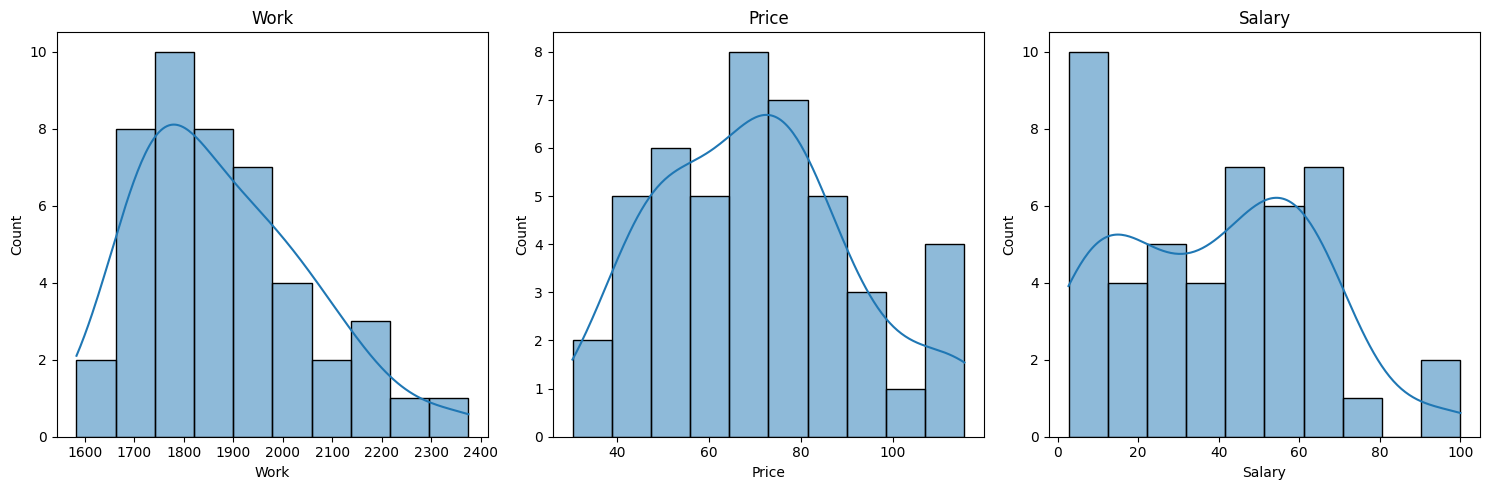

In [6]:
#EDA
plt.figure(figsize=(15, 5))
for i, col in enumerate(features):
    plt.subplot(1, 3, i+1)
    sns.histplot(df_clean[col], bins=10, kde=True, edgecolor='black')
    plt.title(col)
plt.tight_layout()
plt.savefig('eda_hist.png')



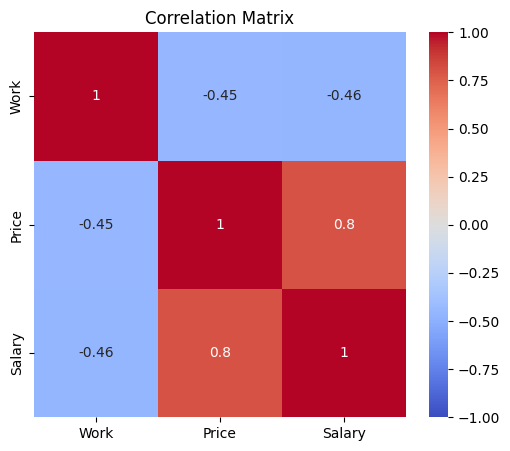

In [7]:
# correlation matrix between features
# матрицы корреляций между признаками
plt.figure(figsize=(6,5))
sns.heatmap(df_clean[features].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.savefig('eda_corr.png')

In [8]:
# Standardize the data because variables have completely different scales
# Стандартизация данных, так как переменные имеют совершенно разные масштабы
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=df_clean.index)

# Calculate the linkage matrix using Ward's method and Euclidean distance
# Вычисление матрицы связей с использованием метода Уорда и евклидова расстояния
Z = linkage(X_scaled, method='ward', metric='euclidean')

k=2: 0.470
k=3: 0.361
k=4: 0.355
k=5: 0.348
k=6: 0.366


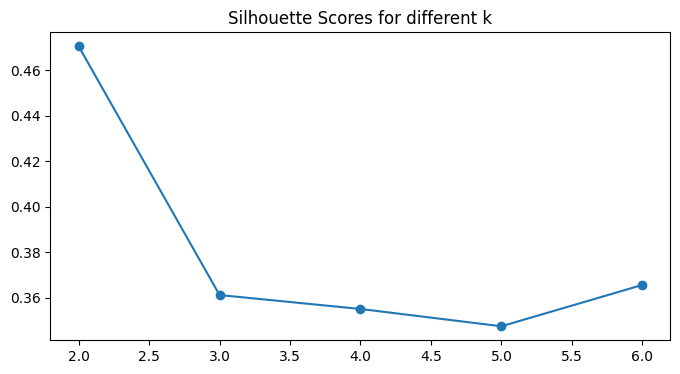

In [9]:
# Evaluate silhouette scores for k=2 to k=6 to find cluster cohesion
# Оценка коэффициентов силуэта для k от 2 до 6 для определения сплоченности кластеров
sil_scores = []
for k in range(2, 7):
    labels = fcluster(Z, k, criterion='maxclust')
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"k={k}: {score:.3f}")

plt.figure(figsize=(8,4))
plt.plot(range(2, 7), sil_scores, marker='o')
plt.title("Silhouette Scores for different k")
plt.savefig('silhouette_curve.png')

In [10]:
# Create Silhouette metrics explicitly for a 3-cluster scenario
# Создание метрик силуэта специально для сценария с 3 кластерами
labels_k3 = fcluster(Z, 3, criterion='maxclust')
sil_vals = silhouette_samples(X_scaled, labels_k3)
df_clean['Cluster_k3'] = labels_k3
df_clean['Sil_Score'] = sil_vals
display(df_clean.head(10))

,Work,Price,Salary,Cluster_k3,Sil_Score
City,,,,,
Amsterdam,1714,65.6,49.0,1,0.080615
Athens,1792,53.8,30.4,2,0.632970
Bogota,2152,37.9,11.5,3,0.427925
Bombay,2052,30.3,5.3,3,0.224357
Brussels,1708,73.8,50.5,1,0.334347
Buenos_Aires,1971,56.1,12.5,3,0.059080
Caracas,2041,61.0,10.9,3,0.335006
Chicago,1924,73.9,61.9,1,0.372870
Copenhagen,1717,91.3,62.9,1,0.550404


In [11]:
# Calculate distance jumps (deltas) to mathematically justify the formation of clusters
# Вычисление скачков расстояния (дельт) для математического обоснования формирования кластеров
heights = Z[:, 2]
deltas = np.diff(heights)

print("=== Mathematical Justification for Clusters / Математическое обоснование ===\n")
print("Top 4 Largest Distance Jumps (Threshold Options):")
for i, delta in enumerate(deltas[-4:][::-1]):
    k = i + 2
    print(f"Jump to form {k} clusters: Delta = {delta:.2f} (Cut-off Y around {heights[-(i+2)]:.2f})")

=== Mathematical Justification for Clusters / Математическое обоснование ===

Top 4 Largest Distance Jumps (Threshold Options):
Jump to form 2 clusters: Delta = 7.34 (Cut-off Y around 5.06)
Jump to form 3 clusters: Delta = 0.20 (Cut-off Y around 4.86)
Jump to form 4 clusters: Delta = 1.20 (Cut-off Y around 3.66)
Jump to form 5 clusters: Delta = 0.26 (Cut-off Y around 3.40)


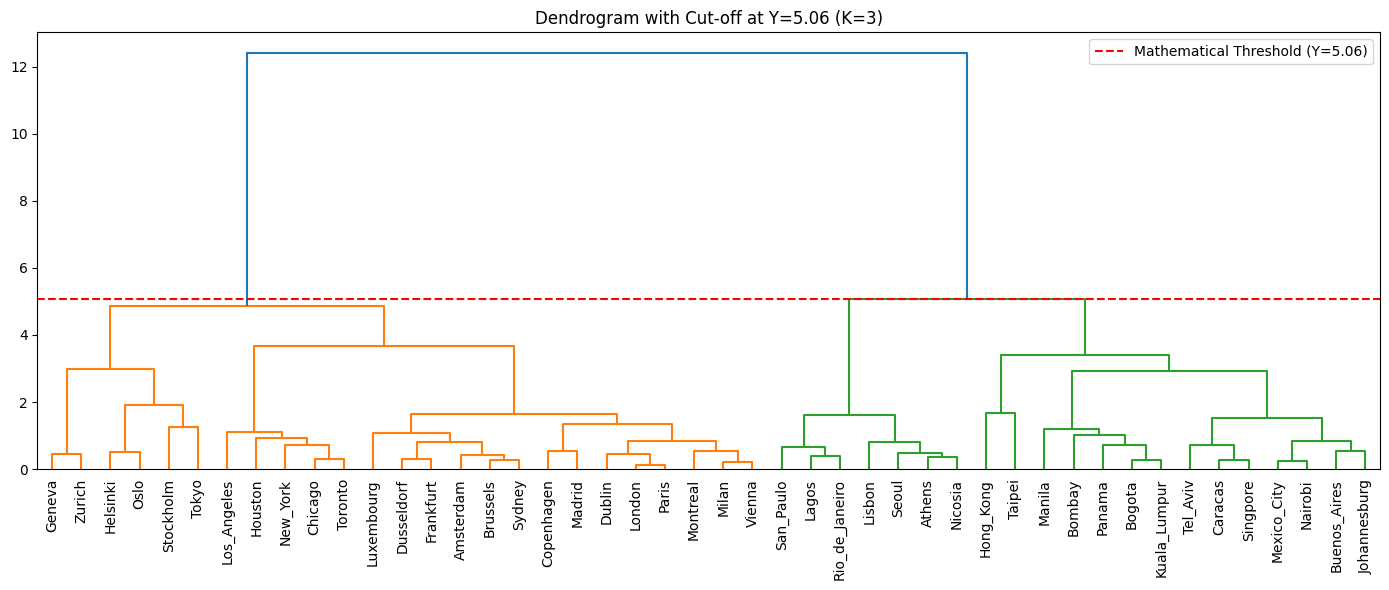

In [12]:
optimal_k = 3
cut_off_y = 5.06 # Garis potong matematika untuk k=3

# Plot the dendrogram with the defined mathematical threshold
# Построение дендрограммы с заданным математическим порогом
plt.figure(figsize=(14, 6))
plt.title(f"Dendrogram with Cut-off at Y={cut_off_y} (K={optimal_k})")
dendrogram(Z, labels=df_clean.index, leaf_rotation=90, leaf_font_size=10)
plt.axhline(y=cut_off_y, color='r', linestyle='--', label=f'Mathematical Threshold (Y={cut_off_y})')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Apply Agglomerative Clustering and assign the final cluster labels
# Применение агломеративной кластеризации и назначение финальных меток кластеров
hc = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
df_clean['Cluster'] = hc.fit_predict(X_scaled)

# Tes Statistik ANOVA
print("=== ANOVA TEST (Statistical Significance) / Тест ANOVA ===\n")
for col in features:

    groups = [df_clean[df_clean['Cluster'] == i][col] for i in df_clean['Cluster'].unique()]
    f_stat, p_val = f_oneway(*groups)
    print(f"{col:<7}: F-value = {f_stat:.2f}, p-value = {p_val:.2e}")

print("\nConclusion: p-values < 0.05 prove the clusters are statistically completely distinct.")

=== ANOVA TEST (Statistical Significance) / Тест ANOVA ===

Work   : F-value = 32.71, p-value = 2.32e-09
Price  : F-value = 30.86, p-value = 4.88e-09
Salary : F-value = 66.98, p-value = 6.17e-14

Conclusion: p-values < 0.05 prove the clusters are statistically completely distinct.


In [14]:
# Re-apply clustering specifically for 3 clusters to ensure state consistency
# Повторное применение кластеризации специально для 3 кластеров для обеспечения согласованности состояния
n_clusters = 3

hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
df_clean['Cluster'] = hc.fit_predict(X_scaled)

In [15]:
# Interpretation: Calculate mean values for each cluster
# Интерпретация: Вычисление средних значений для каждого кластера
cluster_summary = df_clean.groupby('Cluster')[features].mean()
print("Cluster Profiles (Mean Values) / Профили кластеров (Средние значения):")
print(cluster_summary)

Cluster Profiles (Mean Values) / Профили кластеров (Средние значения):
                Work      Price     Salary
Cluster                                   
0        1789.240000  84.972000  59.032000
1        2082.357143  53.121429  14.914286
2        1798.857143  50.942857  19.214286


In [16]:
# Create a summary table
# Создание сводной таблицы
cluster_summary = df_clean.groupby('Cluster')[features].mean().round(0).astype(int)
cluster_summary.insert(0, 'Размер (Size)', df_clean.groupby('Cluster').size())

cluster_names = {
    0: '«Благополучный Запад» (Barat yang Maju/Kaya)',
    1: '«Работают много, получают мало» (Kerja Keras, Gaji Kecil)',
    2: '«Дешёвая периферия» (Periferal/Pinggiran Murah)'
}
cluster_summary.insert(0, 'Название (Nama)', cluster_summary.index.map(cluster_names))

print("Таблица Интерпретации (Tabel Interpretasi):")
display(cluster_summary)


for c in cluster_summary.index:
    cities = df_clean[df_clean['Cluster'] == c].index.tolist()
    print(f"\nКластер {c}: {', '.join(cities)}")


Таблица Интерпретации (Tabel Interpretasi):


,Название (Nama),Размер (Size),Work,Price,Salary
Cluster,,,,,
0,«Благополучный Запад» (Barat yang Maju/Kaya),25,1789,85,59
1,"«Работают много, получают мало» (Kerja Keras, ...",14,2082,53,15
2,«Дешёвая периферия» (Periferal/Pinggiran Murah),7,1799,51,19



Кластер 0: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Кластер 1: Bogota, Bombay, Buenos_Aires, Caracas, Hong_Kong, Johannesburg, Kuala_Lumpur, Manila, Mexico_City, Nairobi, Panama, Singpore, Taipei, Tel_Aviv

Кластер 2: Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul
